<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Preserve the documents behind shredded XML rows

**What disappears when a column of XML becomes a table of item rows?** We will use
the real VGI XSLT worker to audit six authored documents, transform only the intended
namespace, serialize each normalized item, and type its fields in SQL. Empty documents,
wrong namespaces, malformed XML and missing input remain visible in a document audit.

The final chart sums selected, contract-valid item quantities. It keeps unknown
quantities separate and never treats “well formed” as a schema or business-rule check.
All documents and the stylesheet are authored locally; this example fetches no XML,
stylesheet imports, schemas or other resources.

## Choose a minimum quantity for the reporting view

`MIN_QUANTITY=1` includes valid rows with at least one unit. The experiment raises
it to 3. The input documents, transformed records and invalid-row audit stay fixed.
Zero is a valid quantity that may be outside the selected reporting view; missing
or nonnumeric quantities are unknown. Restart and run all after changing this
nonnegative integer.

In [1]:
MIN_QUANTITY = 1

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from notebook_support import finish, prose, theme

if type(MIN_QUANTITY) is not int or not 0 <= MIN_QUANTITY <= 1000:
    raise ValueError("MIN_QUANTITY must be an integer from 0 to 1000.")
coverage = quantities = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-xslt/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-xslt/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-xslt/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-xslt/notebooks/pyproject.toml.

## Attach a pinned Git release and inspect its capabilities

`uvx` installs the public v0.4.0 source revision with explicit runtime pins into
its cache. The worker is not published on PyPI. No checkout-relative worker path
or local package installation is required. SaxonC-HE's native runtime is bundled in
the wheel and may take longer to initialize on first use.

The capabilities row reports XPath 3.1, XQuery 3.1 and XSLT 3.0 support, but
`schema_aware=false`. `is_well_formed` establishes parseability, not XSD validation.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'xslt' (TYPE vgi,LOCATION 'uvx --python 3.14 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --with saxonche==13.1.1 --from git+https://github.com/Query-farm/vgi-xslt@c6384204609d5bb4a7b15b65ca54e73c3f260821 vgi-xslt-worker');
SELECT * FROM xslt.main.saxon_info;

,version,edition,xslt_version,xquery_version,xpath_version,schema_aware
0,SaxonC-HE 13.1 from Saxonica,Home Edition (HE),3.0,3.1,3.1,False


## Separate parseability from document scope

The intended root is `batch` in namespace `urn:orders`. `D2` also contains an
`item` in `urn:telemetry`; it must not become an order item. `D3` is a legitimate
empty batch. `D4` uses the same local names in a different namespace. `D5` cannot
parse and `D6` is SQL NULL.

First materialize parseability. Then materialize only parsed documents before
calling XPath. This keeps malformed input away from functions that raise errors.
EQNames such as `Q{urn:orders}batch` match the exact namespace URI without needing
an arbitrary prefix binding. The wildcard count deliberately shows the broader match.

In [4]:
%%sql
CREATE TABLE documents AS SELECT * FROM (VALUES
 ('D1','<batch xmlns="urn:orders"><item sku="apple" qty="2"/><item sku="pear" qty="5"/></batch>'),
 ('D2','<batch xmlns="urn:orders" xmlns:t="urn:telemetry"><item sku="apple" qty="0"/><item sku="plum" qty="bad"/><item sku="peach"/><item sku="apple" qty="3"/><t:item sku="noise" qty="999"/></batch>'),
 ('D3','<batch xmlns="urn:orders"/>'),
 ('D4','<batch xmlns="urn:other"><item sku="noise" qty="100"/></batch>'),
 ('D5','<batch xmlns="urn:orders"><item></batch>'),
 ('D6',NULL)
) t(document_id,xml);
CREATE TABLE parse_audit AS
SELECT *,xslt.main.is_well_formed(xml) AS well_formed FROM documents;
CREATE TABLE parsed_documents AS SELECT * FROM parse_audit WHERE well_formed IS TRUE;
CREATE TABLE scope_audit AS
SELECT *,xslt.main.xpath_boolean(xml,'exists(/Q{urn:orders}batch)') AS expected_root,
 xslt.main.xpath_number(xml,'count(/Q{urn:orders}batch/Q{urn:orders}item)') AS intended_items,
 xslt.main.xpath_number(xml,'count(//*:item)') AS wildcard_items
FROM parsed_documents;
CREATE TABLE document_audit AS
SELECT p.document_id,p.well_formed,s.expected_root,s.intended_items,s.wildcard_items,
 CASE WHEN p.xml IS NULL THEN 'Missing input'
 WHEN p.well_formed IS FALSE THEN 'Malformed XML'
 WHEN NOT s.expected_root THEN 'Different root namespace'
 WHEN s.intended_items=0 THEN 'In scope; zero items'
 ELSE 'In scope; has items' END AS document_state
FROM parse_audit p LEFT JOIN scope_audit s USING(document_id);
SELECT * FROM document_audit ORDER BY document_id;

,document_id,well_formed,expected_root,intended_items,wildcard_items,document_state
0,D1,True,True,2.0,2.0,In scope; has items
1,D2,True,True,4.0,5.0,In scope; has items
2,D3,True,True,0.0,0.0,In scope; zero items
3,D4,True,False,0.0,1.0,Different root namespace
4,D5,False,<NA>,NaN,NaN,Malformed XML
5,D6,<NA>,<NA>,NaN,NaN,Missing input


In [5]:
%%sql coverage <<
SELECT document_state,count(*) AS documents FROM document_audit
GROUP BY document_state ORDER BY documents DESC,document_state;

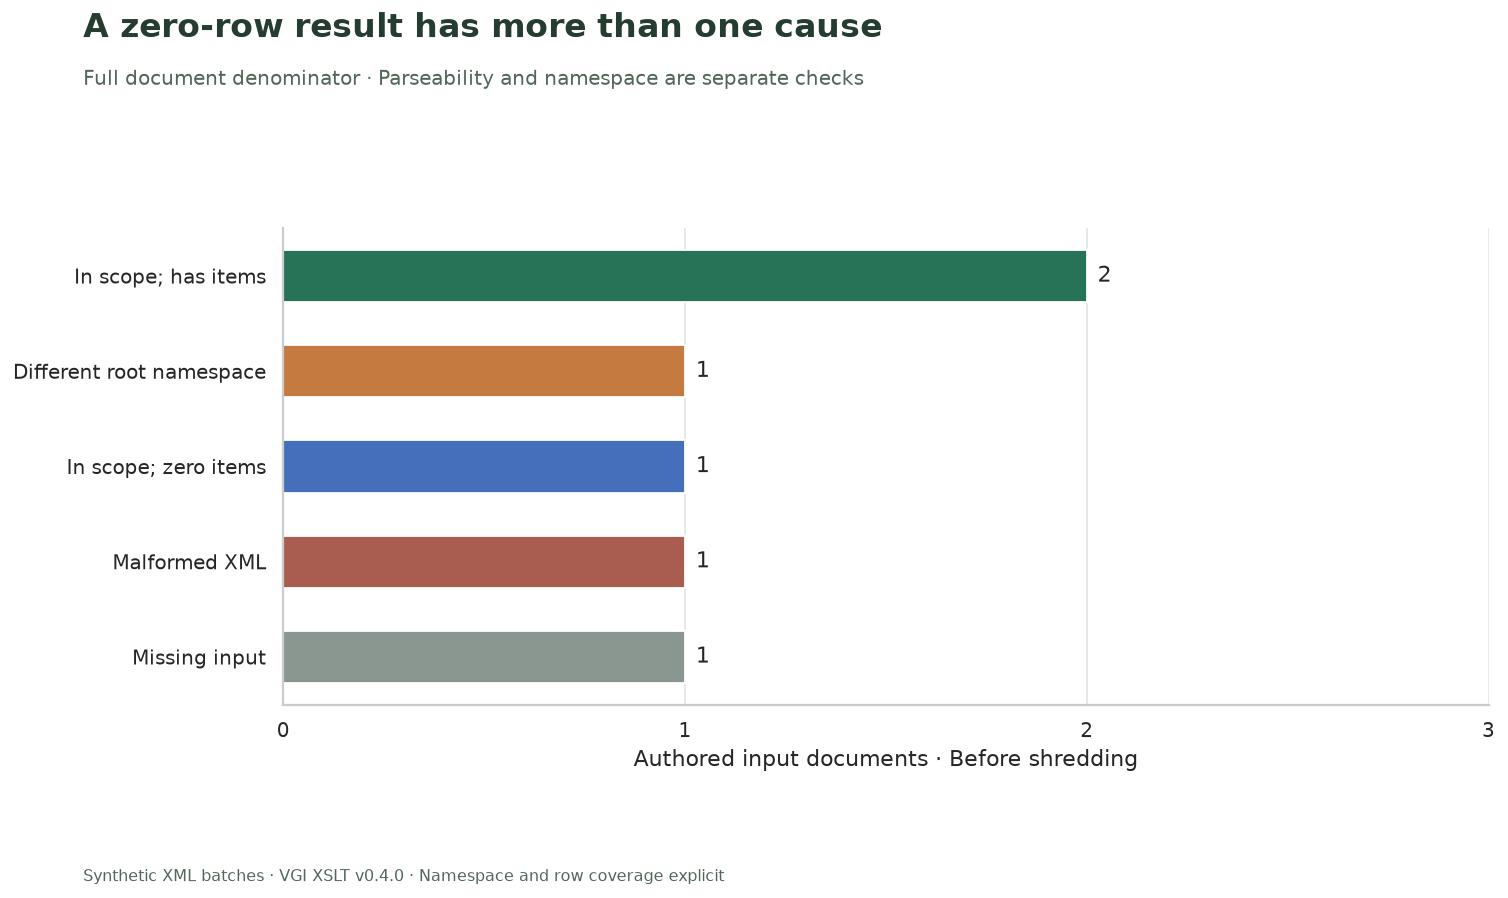

The audit retains **6 documents**. An empty in-scope batch differs from a wrong namespace, malformed XML and missing input. A row-only table would not retain those distinctions. This chart is independent of the quantity filter.

In [6]:
colors = {
    "In scope; has items": "#267358",
    "In scope; zero items": "#456fba",
    "Different root namespace": "#c57b40",
    "Malformed XML": "#a95d50",
    "Missing input": "#8a9790",
}
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(
    coverage.document_state,
    coverage.documents,
    color=[colors[s] for s in coverage.document_state],
    height=0.55,
)
ax.bar_label(bars, padding=6, fontsize=12)
ax.invert_yaxis()
ax.set_xlim(0, int(coverage.documents.max()) + 1)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Authored input documents · Before shredding")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "A zero-row result has more than one cause",
    "Full document denominator · Parseability and namespace are separate checks",
    "01_document_coverage.png",
    bottom=0.12,
)
prose(
    f"The audit retains **{int(coverage.documents.sum())} documents**. "
    "An empty in-scope batch differs from a wrong namespace, malformed XML and missing input. "
    "A row-only table would not retain those distinctions. This chart is independent of the quantity filter."
)

## Normalize item structure with a constant XSLT stylesheet

The stylesheet explicitly selects `o:batch/o:item` using the namespace binding.
It preserves each item's SKU, sequence and raw quantity attribute. `xsl:copy-of`
keeps an absent quantity absent; it does not invent a zero. The empty batch transforms
to an empty `rows` element. The worker caches compiled stylesheets by source text.

Transformation reshapes records. It is not schema validation and does not certify
the quantity's meaning. We will validate a small, explicit quantity contract in SQL.

In [7]:
%%sql
CREATE TABLE stylesheet AS SELECT $style$
<xsl:stylesheet version="3.0" xmlns:xsl="http://www.w3.org/1999/XSL/Transform"
 xmlns:o="urn:orders" exclude-result-prefixes="o">
 <xsl:output method="xml" omit-xml-declaration="yes" indent="no"/>
 <xsl:template match="/">
  <rows><xsl:for-each select="o:batch/o:item">
   <row seq="{position()}" sku="{@sku}"><xsl:copy-of select="@qty"/></row>
  </xsl:for-each></rows>
 </xsl:template>
</xsl:stylesheet>
$style$ AS text;
CREATE TABLE in_scope_documents AS SELECT * FROM scope_audit WHERE expected_root;
CREATE TABLE transformed_documents AS
SELECT document_id,xslt.main.xslt(xml,text) AS normalized_xml
FROM in_scope_documents CROSS JOIN stylesheet;
SELECT * FROM transformed_documents ORDER BY document_id;

,document_id,normalized_xml
0,D1,"<rows><row seq=""1"" sku=""apple"" qty=""2""/><row s..."
1,D2,"<rows><row seq=""1"" sku=""apple"" qty=""0""/><row s..."
2,D3,<rows/>


## Serialize each record before expanding it

`xpath_array` returns each selected item's **string value**. Selecting element nodes
alone does not preserve their markup or attributes. `serialize(.)` explicitly turns
each normalized row into XML text, which is safe to parse again for attributes.

`UNNEST ... WITH ORDINALITY` expands the array and keeps a document-local sequence.
The document ID plus sequence identifies a row. The empty batch yields no rows here,
so we retain `document_audit` and reconcile it with the expanded table afterward.

In [8]:
%%sql
CREATE TABLE shredded AS
SELECT d.document_id,t.ordinality AS item_sequence,t.row_xml
FROM transformed_documents d,
 unnest(xslt.main.xpath_array(d.normalized_xml,'/rows/row ! serialize(.)'))
 WITH ORDINALITY AS t(row_xml,ordinality);
CREATE TABLE raw_items AS
SELECT document_id,item_sequence,xslt.main.xpath_string(row_xml,'/row/@sku') AS sku,
 xslt.main.xpath_string(row_xml,'/row/@qty') AS quantity_text
FROM shredded;
CREATE TABLE typed_items AS
SELECT *,CASE WHEN regexp_full_match(quantity_text,'[0-9]+')
 THEN try_cast(quantity_text AS BIGINT) END AS quantity
FROM raw_items;
CREATE TABLE item_audit AS
SELECT *,CASE WHEN sku IS NULL OR sku='' THEN 'Missing SKU'
 WHEN quantity_text IS NULL THEN 'Missing quantity'
 WHEN quantity IS NULL THEN 'Invalid quantity'
 ELSE 'Valid item' END AS item_state
FROM typed_items;
SELECT * FROM item_audit ORDER BY document_id,item_sequence;

,document_id,item_sequence,sku,quantity_text,quantity,item_state
0,D1,1,apple,2,2,Valid item
1,D1,2,pear,5,5,Valid item
2,D2,1,apple,0,0,Valid item
3,D2,2,plum,bad,<NA>,Invalid quantity
4,D2,3,peach,None,<NA>,Missing quantity
5,D2,4,apple,3,3,Valid item


## Preserve zero, missing and invalid quantities separately

The fixture's quantity contract is a nonnegative whole-number count with a nonempty
SKU. A digits-only check prevents permissive numeric casts from rounding decimals.
The original text remains alongside the typed quantity. Missing and invalid values
stay NULL, while an authored zero remains a valid zero.

The coverage table reconciles expected namespace-matched items with actual shredded
rows. No reported item total includes the telemetry `item` or the other-namespace batch.

In [9]:
%%sql
SELECT a.document_id,a.document_state,a.intended_items,
 count(i.item_sequence) AS shredded_items,
 count(*) FILTER(WHERE i.item_state='Valid item') AS valid_items,
 count(*) FILTER(WHERE i.item_sequence IS NOT NULL AND i.item_state<>'Valid item') AS invalid_items
FROM document_audit a LEFT JOIN item_audit i USING(document_id)
GROUP BY a.document_id,a.document_state,a.intended_items ORDER BY a.document_id;
CREATE TABLE selected_items AS
SELECT * FROM item_audit WHERE item_state='Valid item' AND quantity>={{ MIN_QUANTITY }};
SELECT item_state,count(*) AS items,count(quantity) AS known_quantities
FROM item_audit GROUP BY item_state ORDER BY item_state;

,item_state,items,known_quantities
0,Invalid quantity,1,0
1,Missing quantity,1,0
2,Valid item,4,4


## Report known selected units without hiding unquantified records

The chart sums units only from valid rows meeting the minimum. The output below it
reports the selected row count and the invalid quantity count separately. A missing
quantity is not a zero-unit item, so this is not an estimate of all received units.

The SKU domain comes from all valid records, preserving a zero-height bar when a SKU
has no selected contribution. Zero filling here describes a reporting subset of known
valid rows, not an imputed quantity for an invalid row.

In [10]:
%%sql quantities <<
WITH skus AS (SELECT DISTINCT sku FROM item_audit WHERE item_state='Valid item')
SELECT s.sku,coalesce(sum(i.quantity),0) AS selected_units,count(i.item_sequence) AS selected_rows
FROM skus s LEFT JOIN selected_items i USING(sku) GROUP BY s.sku ORDER BY s.sku;

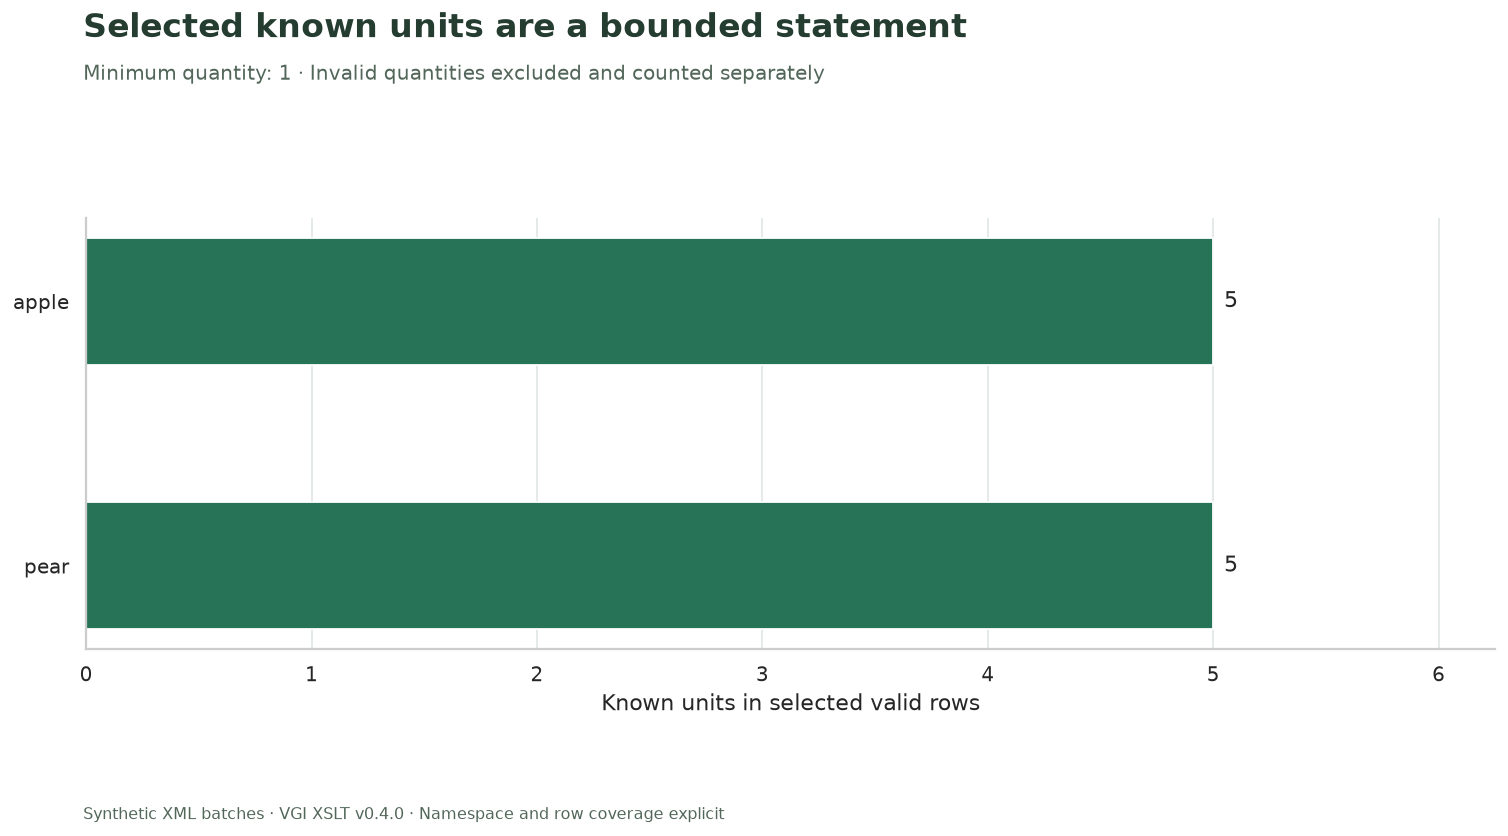

The selected view contains **3 rows** totaling **10 known units**. **2 rows** have missing or invalid quantities and cannot contribute known units. This is a filtered report, not a repaired source document.

,sku,selected_units,selected_rows
0,apple,5.0,2
1,pear,5.0,1


In [11]:
fig, ax = plt.subplots(figsize=(12, 6.5))
bars = ax.barh(quantities.sku, quantities.selected_units, color="#267358", height=0.48)
ax.bar_label(bars, padding=6, fontsize=12)
ax.invert_yaxis()
ax.set_xlim(0, max(1, int(quantities.selected_units.max())) * 1.25)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Known units in selected valid rows")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Selected known units are a bounded statement",
    f"Minimum quantity: {MIN_QUANTITY} · Invalid quantities excluded and counted separately",
    "02_selected_quantities.png",
    bottom=0.12,
)
invalid = con.execute("SELECT count(*) FROM item_audit WHERE item_state<>'Valid item'").fetchone()[
    0
]
prose(
    f"The selected view contains **{int(quantities.selected_rows.sum())} rows** totaling "
    f"**{int(quantities.selected_units.sum())} known units**. **{invalid} rows** have missing or invalid quantities "
    "and cannot contribute known units. This is a filtered report, not a repaired source document."
)
display(quantities)

## Check document coverage, namespace scope and row meaning

The checks preserve the distinction between parsing, structural scope, row contract
and selection. The worker's HE edition still performs no XSD validation.

In [12]:
%%sql checks <<
SELECT 'Every authored document survives the audit' AS check_name,
 (SELECT count(*)=6 AND count(DISTINCT document_id)=6 FROM document_audit) AS passed
UNION ALL SELECT 'Malformed and NULL documents have distinct parse outcomes',
 (SELECT well_formed IS FALSE FROM parse_audit WHERE document_id='D5')
 AND (SELECT well_formed IS NULL FROM parse_audit WHERE document_id='D6')
UNION ALL SELECT 'Exact namespace excludes telemetry item',
 (SELECT intended_items=4 AND wildcard_items=5 FROM scope_audit WHERE document_id='D2')
UNION ALL SELECT 'Same local root name in other namespace stays out of scope',
 (SELECT NOT expected_root AND wildcard_items=1 FROM scope_audit WHERE document_id='D4')
UNION ALL SELECT 'Empty in-scope document transforms but produces no item rows',
 (SELECT count(*)=1 FROM transformed_documents WHERE document_id='D3')
 AND NOT EXISTS(SELECT 1 FROM shredded WHERE document_id='D3')
UNION ALL SELECT 'Only intended namespace items are shredded',
 (SELECT count(*) FROM shredded)=(SELECT sum(intended_items) FROM in_scope_documents)
 AND NOT EXISTS(SELECT 1 FROM raw_items WHERE sku='noise')
UNION ALL SELECT 'Document ID and sequence uniquely identify records',
 NOT EXISTS(SELECT document_id,item_sequence FROM shredded GROUP BY ALL HAVING count(*)<>1)
UNION ALL SELECT 'Missing attribute stays NULL',
 (SELECT quantity_text IS NULL AND quantity IS NULL AND item_state='Missing quantity' FROM item_audit WHERE sku='peach')
UNION ALL SELECT 'Nonnumeric text stays visible and does not become zero',
 (SELECT quantity_text='bad' AND quantity IS NULL AND item_state='Invalid quantity' FROM item_audit WHERE sku='plum')
UNION ALL SELECT 'Known zero remains a valid item',
 (SELECT count(*)=1 FROM item_audit WHERE quantity=0 AND item_state='Valid item')
UNION ALL SELECT 'Selection satisfies the explicit quantity policy',
 NOT EXISTS(SELECT 1 FROM selected_items WHERE item_state<>'Valid item' OR quantity<{{ MIN_QUANTITY }})
 AND (SELECT count(*) FROM selected_items)=(SELECT count(*) FROM item_audit WHERE item_state='Valid item' AND quantity>={{ MIN_QUANTITY }})
UNION ALL SELECT 'Transformed documents remain well formed',
 (SELECT bool_and(xslt.main.is_well_formed(normalized_xml)) FROM transformed_documents);

In [13]:
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert int(coverage.documents.sum()) == con.execute("SELECT count(*) FROM documents").fetchone()[0]
assert (
    int(quantities.selected_rows.sum())
    == con.execute("SELECT count(*) FROM selected_items").fetchone()[0]
)
assert (
    int(quantities.selected_units.sum())
    == con.execute("SELECT coalesce(sum(quantity),0) FROM selected_items").fetchone()[0]
)
prose(
    f"**{len(checks)} SQL checks and all chart reconciliations passed.** Every document remains accounted for even when it produces no selected row."
)

**12 SQL checks and all chart reconciliations passed.** Every document remains accounted for even when it produces no selected row.

## Experiment · raise the reporting minimum

Change only `MIN_QUANTITY` from **1 to 3**, restart, and run all. Predict which valid
row leaves the selected view and how the SKU totals change. The full document chart,
normalized XML, raw quantity text and invalid-item counts should remain identical.

This changes selection, not XML parsing or source quality. Reset `MIN_QUANTITY=1`
for the saved default. To adapt this example, define the namespace and row contract
for your own trusted XML before changing the transformation.

In [14]:
con.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)